#### ESCUELA POLIECTNICA NACIONAL 
#### MTODOS NUMRICOS 
#### DANNY CAIZA 

## DEBER - Interpolacion Y Poinomios de Taylor
23 de Noviembre de 2026
_________________________

### 2. ¿Cuántos términos necesita una calculadora?

#### La serie de Maclaurin de $\sin x$

$$\sin x = \sum_{k=0}^{\infty} \frac{(-1)^k x^{2k+1}}{(2k+1)!} = x - \frac{x^3}{3!} + \frac{x^5}{5!} - \cdots$$

El polinomio de grado $n$ (impar) suma los términos hasta $x^n$. Cada término se obtiene del anterior multiplicando por $\frac{-x^2}{(2k+2)(2k+3)}$.

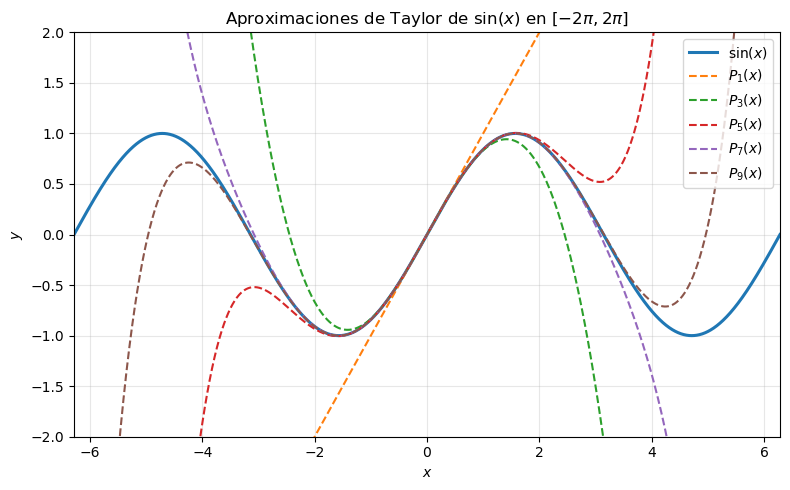

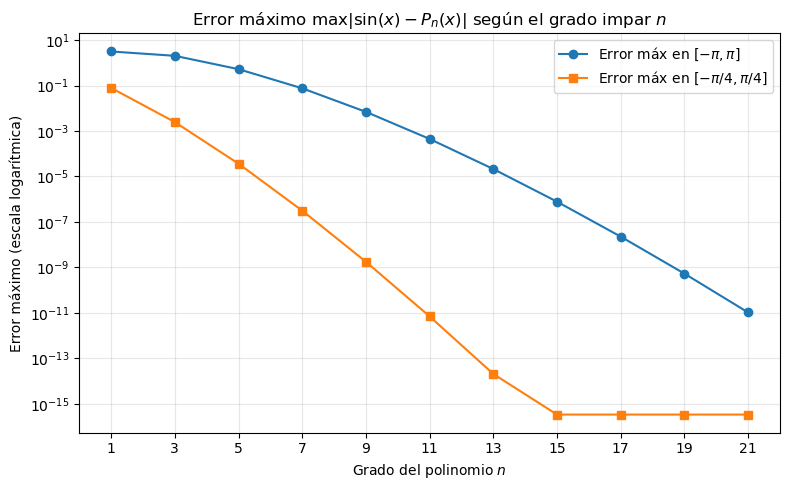

In [ ]:
import matplotlib.pyplot as plt
import numpy as np


def taylor_sin(x, n):
    if n % 2 == 0 or n < 1:
        raise ValueError("n debe ser un entero impar mayor o igual a 1.")

    x_arr = np.asarray(x, dtype=float)
    termino = x_arr.copy()
    suma = termino.copy()

    num_terminos_extra = (n - 1) // 2
    for k in range(num_terminos_extra):
        denominador = (2 * k + 2) * (2 * k + 3)
        termino = termino * (-(x_arr**2)) / denominador
        suma = suma + termino

    if np.ndim(x) == 0:
        return float(suma)
    return suma


x_graf1 = np.linspace(-2 * np.pi, 2 * np.pi, 2001)
grados_graf1 = [1, 3, 5, 7, 9]

plt.figure(figsize=(8, 5))
plt.plot(x_graf1, np.sin(x_graf1), label=r"$\sin(x)$", linewidth=2.2)

for grado in grados_graf1:
    p_n = taylor_sin(x_graf1, grado)
    plt.plot(x_graf1, p_n, linestyle="--", label=rf"$P_{{{grado}}}(x)$")

plt.ylim(-2, 2)
plt.xlim(-2 * np.pi, 2 * np.pi)
plt.title(r"Aproximaciones de Taylor de $\sin(x)$ en $[-2\pi, 2\pi]$")
plt.xlabel(r"$x$")
plt.ylabel(r"$y$")
plt.legend(loc="upper right")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig("grafica_1_taylor_sin.png", dpi=300)
plt.show()

grados_impares = list(range(1, 22, 2))
x_pi = np.linspace(-np.pi, np.pi, 2001)
x_pi4 = np.linspace(-np.pi / 4, np.pi / 4, 2001)

err_max_pi = []
err_max_pi4 = []

for n in grados_impares:
    err_pi = np.max(np.abs(np.sin(x_pi) - taylor_sin(x_pi, n)))
    err_pi4 = np.max(np.abs(np.sin(x_pi4) - taylor_sin(x_pi4, n)))
    err_max_pi.append(err_pi)
    err_max_pi4.append(err_pi4)

plt.figure(figsize=(8, 5))
plt.semilogy(
    grados_impares, err_max_pi, marker="o", label=r"Error máx en $[-\pi, \pi]$"
)
plt.semilogy(
    grados_impares,
    err_max_pi4,
    marker="s",
    label=r"Error máx en $[-\pi/4, \pi/4]$",
)

plt.xticks(grados_impares)
plt.title(r"Error máximo $\max|\sin(x) - P_n(x)|$ según el grado impar $n$")
plt.xlabel(r"Grado del polinomio $n$")
plt.ylabel(r"Error máximo (escala logarítmica)")
plt.legend()
plt.grid(True, which="both", alpha=0.3)
plt.tight_layout()
plt.savefig("grafica_2_error_maximo.png", dpi=300)
plt.show()

### 3. Una función suave cuya serie no converge

#### La serie de Maclaurin de $\frac{1}{1 + x^2}$

La serie geométrica

$$\frac{1}{1 - u} = \sum_{k=0}^{\infty} u^k$$

converge para $|u| < 1$. Con $u = -x^2$ se obtiene la serie de Maclaurin

$$\frac{1}{1 + x^2} = \sum_{k=0}^{\infty} (-1)^k x^{2k} = 1 - x^2 + x^4 - x^6 + \cdots$$

Sea $S_N(x) = \sum_{k=0}^{N} (-1)^k x^{2k}$, un polinomio de grado $2N$.

1. Escriba serie_geometrica(x, N), que devuelve $S_N(x)$ con un término que se actualiza.
2. **Gráfica 3.** $\frac{1}{1 + x^2}$ y $S_N$ para $N = 2, 5, 10, 20$ en $[-1.5, 1.5]$, con el eje vertical limitado a $[-0.5, 1.5]$.

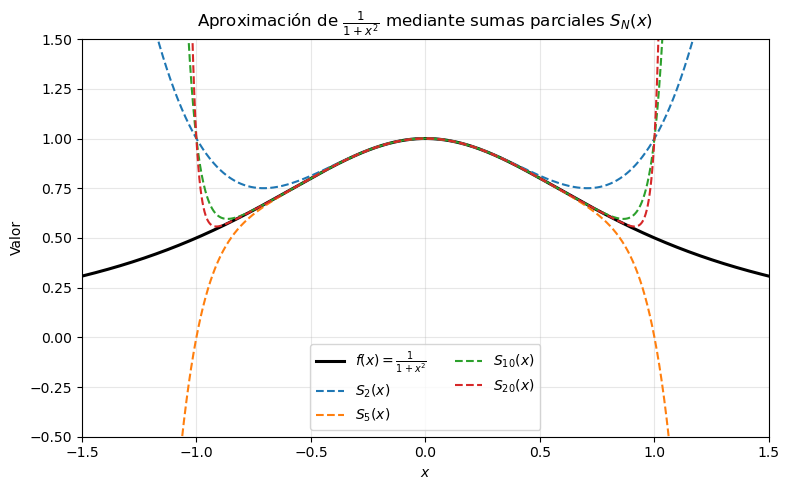

In [ ]:
import matplotlib.pyplot as plt
import numpy as np


def serie_geometrica(x, N):
    if N < 0:
        raise ValueError("N debe ser un entero mayor o igual que 0.")

    x_arr = np.asarray(x, dtype=float)
    termino = np.ones_like(x_arr, dtype=float)
    suma = termino.copy()
    factor = -(x_arr**2)

    for _ in range(N):
        termino = termino * factor
        suma = suma + termino

    return float(suma) if np.ndim(x) == 0 else suma


x_vals = np.linspace(-1.5, 1.5, 2001)
f_vals = 1.0 / (1.0 + x_vals**2)

plt.figure(figsize=(8, 5))
plt.plot(
    x_vals,
    f_vals,
    label=r"$f(x) = \frac{1}{1 + x^2}$",
    linewidth=2.2,
    color="black",
)

for n_val in [2, 5, 10, 20]:
    s_vals = serie_geometrica(x_vals, n_val)
    plt.plot(x_vals, s_vals, linestyle="--", label=rf"$S_{{{n_val}}}(x)$")

plt.xlim(-1.5, 1.5)
plt.ylim(-0.5, 1.5)
plt.title(r"Aproximación de $\frac{1}{1+x^2}$ mediante sumas parciales $S_N(x)$")
plt.xlabel(r"$x$")
plt.ylabel(r"Valor")
plt.legend(loc="lower center", ncol=2)
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

### 4. La serie correcta con la aritmética de la computadora

#### $e^{-20}$ con la serie de Maclaurin

La serie

$$e^x = \sum_{k=0}^{\infty} \frac{x^k}{k!}$$

converge para todo $x$. Calcule $e^{-20}$ sumando los 101 primeros términos ($P_{100}(-20)$) con un término que se actualiza, y compare con `math.exp(-20)` $= 2.061154 \times 10^{-9}$.

In [6]:
import math


def maclaurin_exp(x, N):
    """Calcula P_N(x) = sum_{k=0}^{N} x^k / k! actualizando el término."""
    termino = 1.0
    suma = termino
    for k in range(1, N + 1):
        termino = termino * x / k
        suma = suma + termino
    return suma


p100_neg20 = maclaurin_exp(-20.0, 100)
p100_pos20 = maclaurin_exp(20.0, 100)
inv_p100_pos20 = 1.0 / p100_pos20
exacto = math.exp(-20.0)

max_termino = (20.0**20) / math.factorial(20)

print(f"P_100(-20)       = {p100_neg20:.6e}")
print(f"Mayor |termino|  = {max_termino:.6e}")
print(f"1 / P_100(20)    = {inv_p100_pos20:.6e}")
print(f"math.exp(-20)    = {exacto:.6e}")

P_100(-20)       = 5.621884e-09
Mayor |termino|  = 4.309980e+07
1 / P_100(20)    = 2.061154e-09
math.exp(-20)    = 2.061154e-09
